# 05. Nghiên Cứu Bóc Tách Thành Phần (Ablation Studies: `RQ1`, `RQ2`, `RQ3`)

**Mục tiêu:**
1. **Ablation 1 (`RQ2`):** Phân tích 6 cấu hình lũy tiến (`Config_A` $\to$ `Config_E`) và độ nhạy độ sâu `d = 2, 3, 4` từ `results/ablation1/ablation1_results.json`; trích xuất & trực quan hóa các thế cờ minh họa *Horizon Effect* (`Config_C2` sai vs `Config_D/E` đúng).
2. **Ablation 2A (`RQ3`):** Đường cong độ nhạy ngân sách mô phỏng $N_{\text{sim}} \in \{50, 100, 200, 400, 800, 1000\}$ cho **Cấp 4 (UCT)** và **Cấp 7 (PUCT)** kèm phân tích đánh đổi độ trễ `p95`.
3. **Ablation 2B (`RQ1`):** Bóc tách đóng góp của Policy-only (Cấp 5), Value-only MCTS (Uniform Prior + $V(s)$) và Full Guided MCTS (Cấp 7).

In [1]:
import json
from pathlib import Path
import sys

import chess
from IPython.display import display
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from chess_ai.ui.board_renderer import render_board_image
from chess_ai.utils.epd import load_epd_file

## 1. Ablation 1 — Tầng Tìm Kiếm Cổ Điển Trên Bộ WAC-50 (`RQ2`)

### 1.1. Bảng & Biểu đồ So sánh 6 Cấu hình Lũy tiến (`Config_A` $\rightarrow$ `Config_E`, $d = 3$)

,Cấu hình,Mô tả,Độ chính xác (%),Số thế đúng,Wilson 95% CI,Avg Nodes,Giảm nút (%),Avg TT Hits,Avg ms,p95 ms,Tăng tốc vs Minimax
0,Config_A,Minimax thuần (Negamax không cắt tỉa),50.0,25/50,"[36.6%, 63.4%]",51494.88,0.00,0.00,3073.480,5197.274,1.0x
1,Config_B,Alpha-Beta Pruning,50.0,25/50,"[36.6%, 63.4%]",7129.38,86.16,0.00,423.853,842.150,7.3x
2,Config_C1,"Alpha-Beta + Move Ordering (MVV-LVA, Killer, H...",50.0,25/50,"[36.6%, 63.4%]",2008.60,96.10,0.00,125.314,253.839,24.5x
3,Config_C2,Alpha-Beta + Move Ordering + Zobrist TT (ID),50.0,25/50,"[36.6%, 63.4%]",1967.54,96.18,39.34,124.032,250.407,24.8x
4,Config_D,Config_C2 + Quiescence Search (kèm SEE Pruning),72.0,36/50,"[58.3%, 82.5%]",3611.48,92.99,36.88,154.873,299.772,19.8x
5,Config_E,Cấp 3 hoàn chỉnh (Config_D + PVS + Aspiration ...,72.0,36/50,"[58.3%, 82.5%]",3592.26,93.02,59.18,154.522,294.052,19.9x


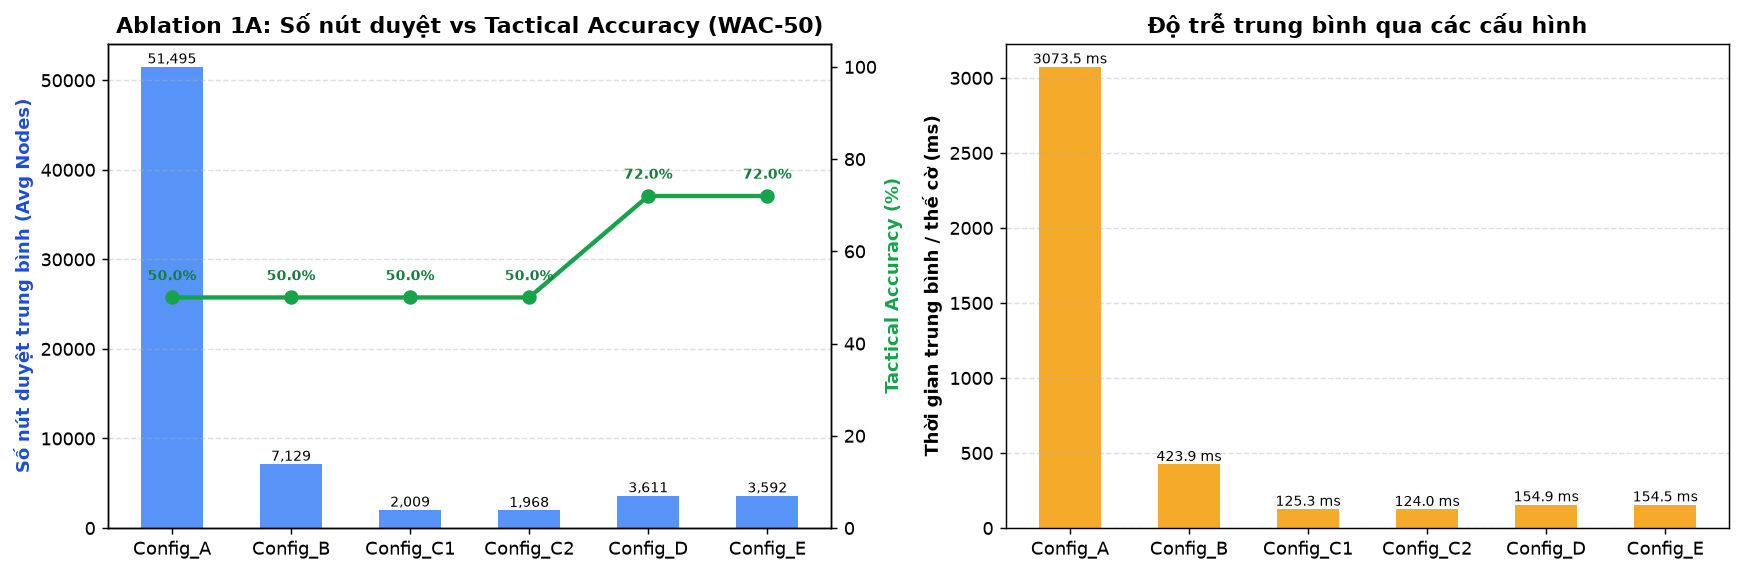

In [2]:
ab1_path = PROJECT_ROOT / "results" / "ablation1" / "ablation1_results.json"
ab1_data = json.loads(ab1_path.read_text(encoding="utf-8"))

part_1a = ab1_data["part_1a_progressive_configs"]
minimax_ms = part_1a[0]["avg_latency_ms"] if part_1a else 1.0

rows_1a = []
for r in part_1a:
    rows_1a.append({
        "Cấu hình": r["name"],
        "Mô tả": r["description"],
        "Độ chính xác (%)": round(r["tactical_accuracy"] * 100.0, 1),
        "Số thế đúng": f"{r['solved_count']}/{r['total_positions']}",
        "Wilson 95% CI": f"[{r['wilson_ci_95'][0]*100:.1f}%, {r['wilson_ci_95'][1]*100:.1f}%]",
        "Avg Nodes": r["avg_nodes"],
        "Giảm nút (%)": r.get("node_reduction_vs_minimax_pct", 0.0),
        "Avg TT Hits": r["avg_tt_hits"],
        "Avg ms": r["avg_latency_ms"],
        "p95 ms": r["p95_latency_ms"],
        "Tăng tốc vs Minimax": f"{minimax_ms / max(0.01, r['avg_latency_ms']):.1f}x",
    })

df_1a = pd.DataFrame(rows_1a)
display(df_1a)

# Biểu đồ cột (Avg Nodes) + đường (Tactical Accuracy) và Độ trễ trung bình
fig, (ax_left, ax_right) = plt.subplots(1, 2, figsize=(13.5, 4.5), dpi=130)

names = [r["name"] for r in part_1a]
avg_nodes = [r["avg_nodes"] for r in part_1a]
accs = [r["tactical_accuracy"] * 100.0 for r in part_1a]
avg_ms = [r["avg_latency_ms"] for r in part_1a]

bars = ax_left.bar(names, avg_nodes, color="#3B82F6", alpha=0.85, width=0.52)
ax_left.set_ylabel("Số nút duyệt trung bình (Avg Nodes)", color="#1D4ED8", fontweight="bold")
ax_left.set_title("Ablation 1A: Số nút duyệt vs Tactical Accuracy (WAC-50)", fontweight="bold")
ax_left.grid(axis="y", linestyle="--", alpha=0.4)

ax_acc = ax_left.twinx()
ax_acc.plot(names, accs, color="#16A34A", marker="o", linewidth=2.4, markersize=7)
ax_acc.set_ylabel("Tactical Accuracy (%)", color="#16A34A", fontweight="bold")
ax_acc.set_ylim(0, 105)

for b, v in zip(bars, avg_nodes):
    ax_left.text(b.get_x() + b.get_width() / 2, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=8)
for i, a in enumerate(accs):
    ax_acc.text(i, a + 3.0, f"{a:.1f}%", ha="center", va="bottom", fontsize=8, color="#15803D", fontweight="bold")

bars_ms = ax_right.bar(names, avg_ms, color="#F59E0B", alpha=0.88, width=0.52)
ax_right.set_ylabel("Thời gian trung bình / thế cờ (ms)", fontweight="bold")
ax_right.set_title("Độ trễ trung bình qua các cấu hình", fontweight="bold")
ax_right.grid(axis="y", linestyle="--", alpha=0.4)
for b, v in zip(bars_ms, avg_ms):
    ax_right.text(b.get_x() + b.get_width() / 2, v, f"{v:.1f} ms", ha="center", va="bottom", fontsize=8)

fig.tight_layout()
plt.show()

### 1.2. Khảo sát Độ nhạy theo Độ sâu $d \in \{2, 3, 4\}$ (`Config_E`)

,Độ sâu,Độ chính xác (%),Số thế đúng,Wilson 95% CI,Avg Nodes,Avg ms,p95 ms
0,d = 2,58.0,29/50,"[44.2%, 70.6%]",630.84,33.199,68.437
1,d = 3,72.0,36/50,"[58.3%, 82.5%]",3592.26,154.340,291.997
2,d = 4,86.0,43/50,"[73.8%, 93.0%]",12170.38,598.277,1382.164


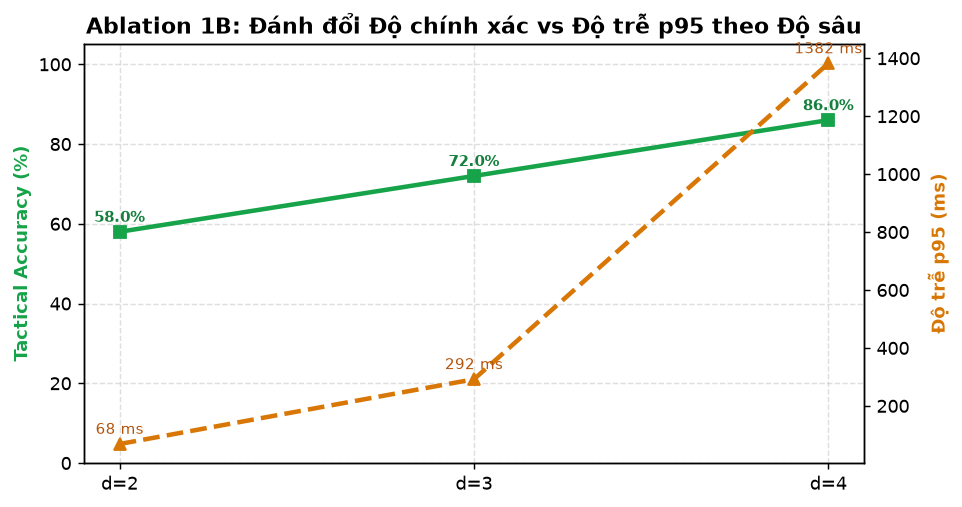

In [3]:
part_1b = ab1_data["part_1b_depth_sensitivity"]
df_1b = pd.DataFrame([
    {
        "Độ sâu": f"d = {r['depth']}",
        "Độ chính xác (%)": round(r["tactical_accuracy"] * 100.0, 1),
        "Số thế đúng": f"{r['solved_count']}/{r['total_positions']}",
        "Wilson 95% CI": f"[{r['wilson_ci_95'][0]*100:.1f}%, {r['wilson_ci_95'][1]*100:.1f}%]",
        "Avg Nodes": r["avg_nodes"],
        "Avg ms": r["avg_latency_ms"],
        "p95 ms": r["p95_latency_ms"],
    }
    for r in part_1b
])
display(df_1b)

depths = [f"d={r['depth']}" for r in part_1b]
accs_1b = [r["tactical_accuracy"] * 100.0 for r in part_1b]
p95_1b = [r["p95_latency_ms"] for r in part_1b]

fig, ax1 = plt.subplots(figsize=(7.5, 4.0), dpi=130)
ax2 = ax1.twinx()
ax1.plot(depths, accs_1b, marker="s", markersize=7, color="#16A34A", linewidth=2.5, label="Accuracy (%)")
ax1.set_ylabel("Tactical Accuracy (%)", color="#16A34A", fontweight="bold")
ax1.set_ylim(0, 105)
ax1.set_title("Ablation 1B: Đánh đổi Độ chính xác vs Độ trễ p95 theo Độ sâu", fontweight="bold")
ax1.grid(True, linestyle="--", alpha=0.4)

ax2.plot(depths, p95_1b, marker="^", markersize=7, linestyle="--", color="#D97706", linewidth=2.5, label="p95 Latency (ms)")
ax2.set_ylabel("Độ trễ p95 (ms)", color="#D97706", fontweight="bold")
for i, (a, p) in enumerate(zip(accs_1b, p95_1b)):
    ax1.text(i, a + 2.5, f"{a:.1f}%", ha="center", color="#15803D", fontsize=8.5, fontweight="bold")
    ax2.text(i, p + 35, f"{p:.0f} ms", ha="center", color="#B45309", fontsize=8.5)

fig.tight_layout()
plt.show()

### 1.3. Phân tích Hiện tượng Mù Chân Trời (*Horizon Effect*): `Config_C2` (Tắt Quiescence) vs `Config_E` (Bật Quiescence)

Liệt kê các thế cờ `WAC` mà `Config_C2` giải sai tại $d=3$ nhưng `Config_E` (và `Config_D`) giải đúng nhờ mở rộng tìm kiếm tĩnh chuỗi bắt quân/chiếu tại nút lá, kèm minh họa trực quan 4 thế cờ đầu tiên.

Số thế cờ được giải cứu nhờ Quiescence Search (C2 sai -> E đúng): 13 / 50


,Mã thế cờ,Nước chuẩn (bm),Config_C2 chọn (Sai),Config_E chọn (Đúng),Nodes C2,Nodes E
0,WAC.006,b6b7,b6b8,b6b7,431,757
1,WAC.007,g4e3,g4e5,g4e3,1307,3422
2,WAC.008,e7f7,h6f7,e7f7,1649,3683
3,WAC.013,f1f8,f1e1,f1f8,1623,2216
4,WAC.015,b8b7,c1d1,b8b7,965,1943
5,WAC.017,c4e5,c1f4,c4e5,4369,5054
6,WAC.022,"c4a2, g5f7",c4b5,g5f7,1812,4327
7,WAC.029,c5c6,f4g5,c5c6,3866,6118
8,WAC.034,d4g1,b7e4,d4g1,1997,4683
9,WAC.036,e7e1,d6d4,e7e1,1155,2359


pygame 2.6.1 (SDL 2.28.4, Python 3.11.16)
Hello from the pygame community. https://www.pygame.org/contribute.html


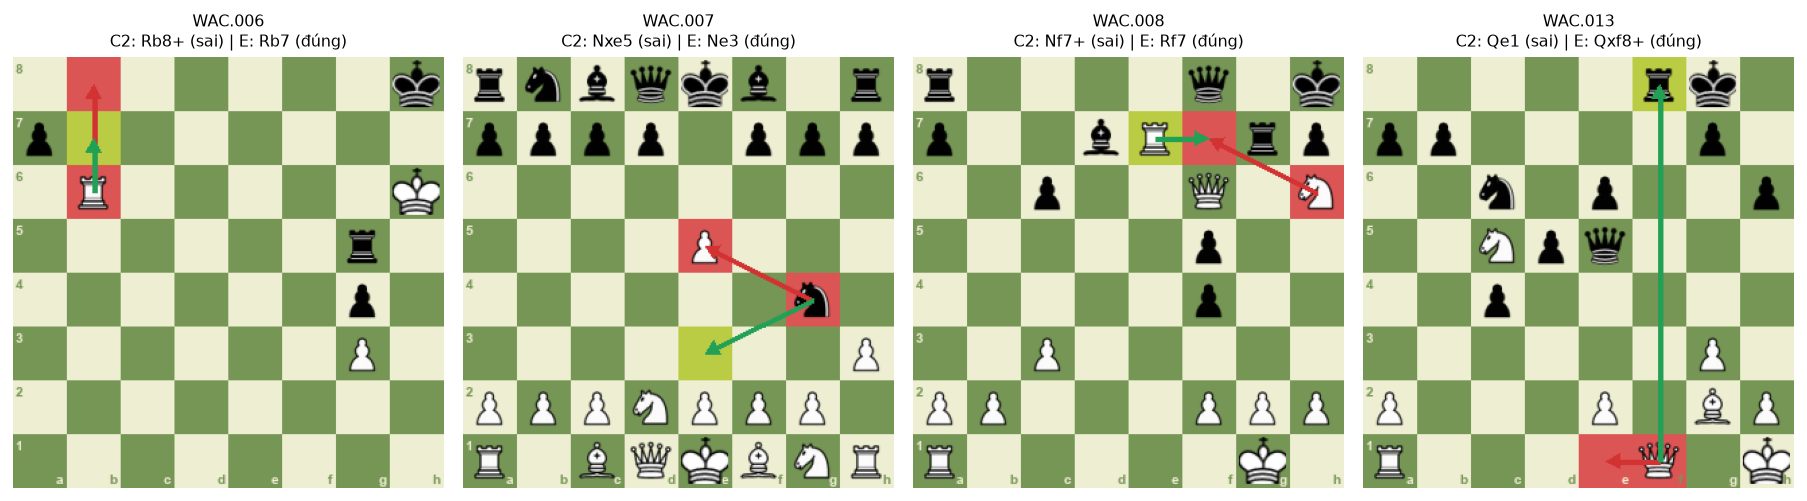

In [4]:
cfg_map = {r["name"]: r for r in part_1a}
c2_pos = {p["id"]: p for p in cfg_map["Config_C2"]["positions"]}
e_pos = {p["id"]: p for p in cfg_map["Config_E"]["positions"]}
wac_map = {rec.record_id: rec for rec in load_epd_file(PROJECT_ROOT / "resources" / "benchmark_positions.epd")}

horizon_cases = []
for pid, p_e in e_pos.items():
    p_c2 = c2_pos[pid]
    if (not p_c2["solved"]) and p_e["solved"]:
        horizon_cases.append({
            "Mã thế cờ": pid,
            "Nước chuẩn (bm)": ", ".join(p_e["expected_moves"]),
            "Config_C2 chọn (Sai)": p_c2["found_move"],
            "Config_E chọn (Đúng)": p_e["found_move"],
            "Nodes C2": p_c2["nodes"],
            "Nodes E": p_e["nodes"],
        })

print(f"Số thế cờ được giải cứu nhờ Quiescence Search (C2 sai -> E đúng): {len(horizon_cases)} / {len(e_pos)}")
display(pd.DataFrame(horizon_cases))

# Vẽ minh họa 4 thế cờ đầu tiên (mũi tên đỏ: nước sai của Config_C2 | mũi tên xanh: nước đúng của Config_E)
sample_cases = horizon_cases[:4]
if sample_cases:
    fig, axes = plt.subplots(1, len(sample_cases), figsize=(14, 4.0), dpi=130)
    if len(sample_cases) == 1:
        axes = [axes]
    for ax, case in zip(axes, sample_cases):
        pid = case["Mã thế cờ"]
        b = chess.Board(wac_map[pid].fen)
        m_good = chess.Move.from_uci(case["Config_E chọn (Đúng)"])
        m_bad = chess.Move.from_uci(case["Config_C2 chọn (Sai)"])
        ax.imshow(render_board_image(b, move=m_good, bad_move=m_bad, board_size=320))
        ax.set_title(f"{pid}\nC2: {b.san(m_bad)} (sai) | E: {b.san(m_good)} (đúng)", fontsize=9)
        ax.axis("off")
    fig.tight_layout()
    plt.show()

## 2. Ablation 2 — Độ Nhạy `N_sim` (Cấp 4 vs Cấp 7) & Bóc Tách Policy/Value (`RQ1`, `RQ3`)

,Agent,N_sim,Score (%),W/D/L,Wilson 95% CI,Avg ms
0,Level4_MCTS_UCT,50,0.0,0/0/50,"[0.0%, 7.1%]",168.2
1,Level4_MCTS_UCT,100,0.0,0/0/50,"[0.0%, 7.1%]",347.4
2,Level4_MCTS_UCT,200,0.0,0/0/50,"[0.0%, 7.1%]",742.4
3,Level4_MCTS_UCT,400,0.0,0/0/50,"[0.0%, 7.1%]",1375.2
4,Level4_MCTS_UCT,800,2.0,1/0/49,"[0.4%, 10.5%]",2689.7
5,Level4_MCTS_UCT,1000,2.0,0/2/48,"[0.4%, 10.5%]",3304.9


,Agent,N_sim,Score (%),W/D/L,Wilson 95% CI,Avg ms
0,Level7_GuidedMCTS,50,62.0,22/18/10,"[48.1%, 74.1%]",30.3
1,Level7_GuidedMCTS,100,73.0,27/19/4,"[59.4%, 83.3%]",56.0
2,Level7_GuidedMCTS,200,84.0,35/14/1,"[71.5%, 91.7%]",110.9
3,Level7_GuidedMCTS,400,79.0,34/11/5,"[65.9%, 88.0%]",232.4
4,Level7_GuidedMCTS,800,85.0,37/11/2,"[72.6%, 92.4%]",508.1
5,Level7_GuidedMCTS,1000,86.0,39/8/3,"[73.8%, 93.0%]",642.3



--- Phần 2B: Bóc tách Policy-only (Cấp 5) vs Value-only MCTS vs Guided MCTS (Cấp 7) ---


,Cặp đấu,Số ván,Score (%),W/D/L,Wilson 95% CI,Bootstrap 95% CI,Agent A Avg ms
0,Level7_GuidedMCTS vs Level5_Supervised,100,94.5,89/11/0,"[88.2%, 97.5%]","[91.0%, 97.5%]",56.9
1,Level7_ValueOnlyMCTS vs Level5_Supervised,100,31.5,4/55/41,"[23.2%, 41.1%]","[26.0%, 37.0%]",60.1
2,Level7_GuidedMCTS vs Level7_ValueOnlyMCTS,100,96.5,94/5/1,"[90.8%, 98.7%]","[93.5%, 99.0%]",57.1


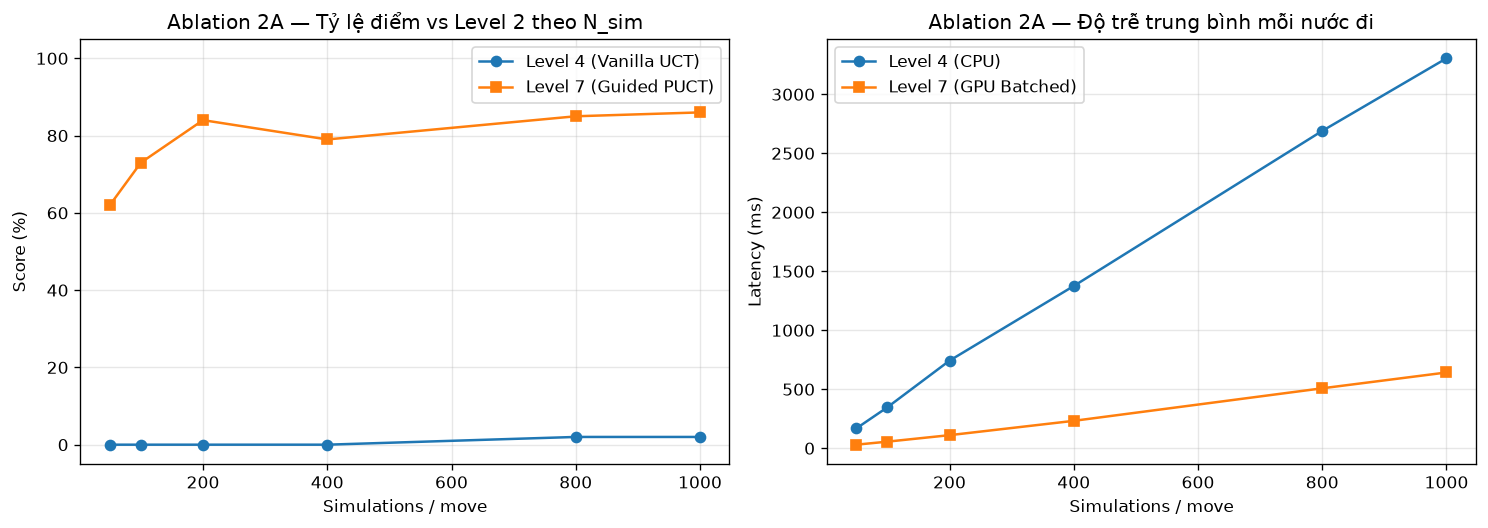

In [5]:
ab2_path = PROJECT_ROOT / "results" / "ablation2" / "ablation2_results.json"
if ab2_path.exists():
    ab2_data = json.loads(ab2_path.read_text(encoding="utf-8"))
    uct_rows = ab2_data.get("part_2a_uct_level4", [])
    if uct_rows:
        display(pd.DataFrame([
            {"Agent": "Level4_MCTS_UCT", "N_sim": r["simulations"], "Score (%)": round(r["score"] * 100, 1), "W/D/L": f"{r['wins']}/{r['draws']}/{r['losses']}", "Wilson 95% CI": f"[{r['wilson_ci_95'][0]*100:.1f}%, {r['wilson_ci_95'][1]*100:.1f}%]", "Avg ms": round(r["agent_a_avg_latency_ms"], 1)}
            for r in uct_rows
        ]))
    puct_rows = ab2_data.get("part_2a_puct_level7", {}).get("curve", [])
    if puct_rows:
        display(pd.DataFrame([
            {"Agent": "Level7_GuidedMCTS", "N_sim": r["simulations"], "Score (%)": round(r["score"] * 100, 1), "W/D/L": f"{r['wins']}/{r['draws']}/{r['losses']}", "Wilson 95% CI": f"[{r['wilson_ci_95'][0]*100:.1f}%, {r['wilson_ci_95'][1]*100:.1f}%]", "Avg ms": round(r["agent_a_avg_latency_ms"], 1)}
            for r in puct_rows
        ]))
    part_2b = ab2_data.get("part_2b_guidance_ablation", {}).get("matchups", [])
    if part_2b:
        print("\n--- Phần 2B: Bóc tách Policy-only (Cấp 5) vs Value-only MCTS vs Guided MCTS (Cấp 7) ---")
        display(pd.DataFrame([
            {"Cặp đấu": f"{m['agent_a']} vs {m['agent_b']}", "Số ván": m["games"], "Score (%)": round(m["score"] * 100, 1), "W/D/L": f"{m['wins']}/{m['draws']}/{m['losses']}", "Wilson 95% CI": f"[{m['wilson_ci_95'][0]*100:.1f}%, {m['wilson_ci_95'][1]*100:.1f}%]", "Bootstrap 95% CI": f"[{m['bootstrap_ci_95'][0]*100:.1f}%, {m['bootstrap_ci_95'][1]*100:.1f}%]", "Agent A Avg ms": round(m["agent_a_avg_latency_ms"], 1)}
            for m in part_2b
        ]))
    if uct_rows and puct_rows:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.5), dpi=120)
        ax1.plot([r["simulations"] for r in uct_rows], [r["score"] * 100 for r in uct_rows], marker="o", label="Level 4 (Vanilla UCT)")
        ax1.plot([r["simulations"] for r in puct_rows], [r["score"] * 100 for r in puct_rows], marker="s", label="Level 7 (Guided PUCT)")
        ax1.set_title("Ablation 2A — Tỷ lệ điểm vs Level 2 theo N_sim"); ax1.set_xlabel("Simulations / move"); ax1.set_ylabel("Score (%)"); ax1.set_ylim(-5, 105); ax1.grid(True, alpha=0.3); ax1.legend()
        ax2.plot([r["simulations"] for r in uct_rows], [r["agent_a_avg_latency_ms"] for r in uct_rows], marker="o", label="Level 4 (CPU)")
        ax2.plot([r["simulations"] for r in puct_rows], [r["agent_a_avg_latency_ms"] for r in puct_rows], marker="s", label="Level 7 (GPU Batched)")
        ax2.set_title("Ablation 2A — Độ trễ trung bình mỗi nước đi"); ax2.set_xlabel("Simulations / move"); ax2.set_ylabel("Latency (ms)"); ax2.grid(True, alpha=0.3); ax2.legend()
        plt.tight_layout()
        plt.show()
else:
    print(f"Chưa tìm thấy {ab2_path}.")
